# AMC 2026 – Round 3 · Notebook 2: the quant strategy (BABQM)
Matterhorn Capital Management · Group 3 · built on the notebook of TA session 6

## Goal
Starting from the Round 2 portfolio, add our **quantitative factor strategy** (Class 6), **BABQM**: the Russell 1000 stocks that are low-beta, high-quality and rising. We specify it, backtest it with the **Class 4 protocol**, and size it inside the **tracking-error budget**.

The data come from `r3_bloomberg.xlsx` → `01_bloomberg_data.ipynb` (CSV files in this folder). §1–§5 need only the backtest and run now; §6–§8 need the Bloomberg refresh of Saturday 28 November.

## The Round 3 guidelines (recap)
**Key dates**

| When | What |
|---|---|
| Sat 28 – Sun 29 November | insert the new positions in Bloomberg (**PRTU**): prices of **Friday 27 November** |
| **Sun 29 November, 23:59** | report + code + portfolio description; upload them to our website |
| Tue 1 Dec 11:00 (room 253) | our presentation (groups 1–5), about 10 minutes, all members |
| until **27 December** | the portfolio cannot change: this is the last round |

**The task**
- Add **two** tactical strategies, the portfolio must contain **both**: a **quantitative** strategy built with EQS and backtested with EQBT (**Class 6**, factor ETFs not allowed), and a **macro** strategy (**Class 7**).
- **Long-only.** The **SAA of Round 1 does not change**: it is the reference for all the deviations.
- **Round 2 stocks:** keep or close each one, and say why (catalyst occurred? valuation still holds?).

**The tracking-error budget**
- **Ex-ante TE against the SAA ≤ 7% per year**, for all the deviations **together**: the Round 2 stocks we keep + the quant strategy + the macro strategy.
- Monthly returns in USD, annualized, last 60 months where available. Report the ex-ante **volatility** and the **one-month 5% VaR** next to the SAA's.

## Where each requirement is in this notebook
| Requirement | Section |
|---|---|
| Checkpoint 1: factor and rationale | §1 |
| Checkpoint 1: construction rule (long-only) | §2 |
| Checkpoint 1: backtest: design, validation, risk, discount | §3, §4, §5 |
| Today's stocks | §6 |
| Round 2 stocks: keep or close | §0 (`W_R2`) |
| TE ≤ 7%, volatility and VaR vs the SAA | §7 |
| Portfolio description and trades | §8 |
| Checkpoint 2 (macro) | macro notebooks (`Round 3 AMC/Macro/`) |

## 0. Settings

In [1]:
import numpy as np                     # arrays and matrix algebra
import pandas as pd                    # tables with dates
import matplotlib.pyplot as plt        # plots
pd.set_option("display.float_format", "{:.4f}".format)

STRAT, BENCH = "BABQM", "Russell 1000" # columns of r3_backtest.csv (notebook 01)

# SAA of Round 1 (data/holdings.json, target weights): unchanged in Round 3, the benchmark of every deviation
W_SAA = pd.Series({"VTI": 0.1090, "VEA": 0.1024, "IEMG": 0.1023, "BND": 0.1333,
                   "BNDX": 0.1648, "TIP": 0.1526, "GLD": 0.1115, "BCI": 0.1240})   # BIL 0%; the rest (0.01%) is cash
ETFS = list(W_SAA.index)

# Round 2 portfolio, as entered in PRTU on 8 Nov 2026 (closes of 6 Nov); shares and cash checked against PORT on 28 Nov (B6)
OLD_SHARES = pd.Series({"VTI": 23084, "VEA": 115597, "IEMG": 108607, "BND": 142724, "BNDX": 265436,
                        "TIP": 110068, "GLD": 22942, "BCI": 385745,
                        "NVDA": 9618, "PEP": 54063, "ABBV": 19594, "DRI": 28349})
CASH_R2 = 8_707.90
# Round 2 stocks (A4, 27 Nov): all four kept, each cut to 2% of the NAV (0 would close it). Reasons per stock in the report
W_R2 = {"NVDA": 0.02, "PEP": 0.02, "ABBV": 0.02, "DRI": 0.02}
PRICE_DATE = "2026-11-27"              # Bloomberg prices the Round 3 trades at the closes of Friday 27 November

WINDOW   = 60                          # months, as in Rounds 1 and 2
SPLIT    = "2015-12-31"                # Class 4: tune on 2006-2015, validate on 2016-2026
N_EXTRA  = 0                           # Class 4: backtests we ran that are NOT in Tested Strategies.xlsx (none: all 9 logged)
DISCOUNT = 0.5                         # Class 4 rule of thumb: divide the backtested Sharpe Ratio by 2
TE_MAX, TE_QUANT = 0.07, 0.05          # Round 3 budget, and the TE of Round 2 stocks + quant before the macro sleeve
W_Q_MAX  = 0.125                       # cap on the quant sleeve, in % of the NAV: team decision of 28 Nov (reasons in §7)

## 1. The factors and their rationale (Checkpoint 1, part 1)
A **factor** is a characteristic of a stock that helps predict its return: sort many stocks on it, and the top group earns more than the bottom group on average. The checkpoint asks **why** it should earn more:

| | **Risk** | **Behavioural** |
|---|---|---|
| Idea | a payment for holding a risk investors dislike | a profit from a mistake (or a constraint) investors keep having |
| Will it last? | yes, as long as the risk exists | only while the mistake lasts and is hard to trade away |

**BABQM is a defensive multi-factor strategy:** buy the stocks that are **low-beta**, **high-quality** and **rising**. Low-beta stocks earn about as much as high-beta stocks with less risk. Quality and momentum remove the low-beta stocks that are calm for a bad reason: weak profits, or a price already falling (the "defensive trap").

### 1a. Low beta: betting against beta (the core factor)
- **Signal:** the beta of each stock against the **S&P 500**: Bloomberg's **adjusted beta** `EQY_BETA` (EXP1 in §2). **Low** beta = high rank.
$$\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}$$
  $\beta_i = 0.6$: when the market moves 1%, the stock moves on average 0.6%. The adjusted beta shrinks the raw estimate toward 1, $\beta^{adj} = 0.67\,\beta^{raw} + 0.33$, which does not change the ranking.
- **Evidence:** the security market line is too flat. Low-beta stocks earn more than the CAPM predicts and high-beta stocks less (Frazzini and Pedersen, 2014, *Betting against beta*). The same holds for low volatility (Blitz and van Vliet, 2007, *The volatility effect*).
- **Why it should pay (behavioural / constraints):** many investors cannot or will not borrow. To aim for a higher return they buy high-beta stocks instead of using leverage, so those become too expensive and the low-beta ones too cheap. Benchmarked managers make it worse: a low-beta stock adds tracking error, so they avoid it. A long-only fund can harvest the effect without any leverage.
- **Risk story:** weak, since these stocks are *less* risky. Frazzini and Pedersen link the BAB return to funding conditions: it suffers when borrowing gets harder.
- **Main risks:** with a beta below 1 the portfolio **lags strong rallies**. Low-beta sectors (utilities, staples, health care) also behave a bit like bonds and **fall when yields rise**. Betas are noisy estimates.

### 1b. Quality: buy profitable firms
- **Signal:** the **return on assets** of the last 12 months, `RETURN_ON_ASSET(FUND_PER='LTM')`: net income over average total assets, in %. **High** = high rank.
- **Evidence:** safe, profitable, growing firms earn higher risk-adjusted returns (Asness, Frazzini and Pedersen, 2019, *Quality minus junk*; Novy-Marx, 2013, for gross profitability).
- **Why it should pay (behavioural):** investors chase exciting stories and overlook dull, profitable firms, so these end up too cheap. A risk story is hard to argue: profitable firms are *less* risky.
- **Its job in BABQM:** it removes the low-beta firms that are calm only because their business is weak.
- **Main risk:** in rebounds after a crash ("junk rallies") the weakest stocks rise most and quality lags.

### 1c. Momentum: buy recent winners
- **Signal:** the **12-1 month return**: the total return of the last 12 months without the last month, $(1 + R_{12m})/(1 + R_{1m}) - 1$, from `TOTAL_RETURN` over `1Y` and `1M`. This is the academic version: it skips the last month, because very recent winners tend to fall back a little. **High** = high rank.
- **Evidence:** Jegadeesh and Titman (1993). In Class 6, the Mom factor has a Sharpe of 0.46 since 1927 and an alpha of 9.9% with t = 6.4 (Exercise B).
- **Why it should pay (behavioural):** investors react slowly to news, so prices keep moving in the same direction for a while; then others jump on the trend and push it further.
- **Its job in BABQM:** it keeps out the defensive stocks whose price is already falling, and it is the catalyst: the market has started to reward the stock.
- **Main risks:** **momentum crashes** when the market rebounds sharply after a fall (Class 6, Exercise C: April 2009 −34.4%), and turnover: the list changes every month.

### 1d. Why combine them, and why now
- **The combination has a track record:** low risk with momentum and shareholder yield is the "Conservative Formula" (van Vliet and Blitz, 2018); low beta with quality is the basis of defensive-equity funds (e.g. AQR).
- **In our backtest (§3):** adding quality and momentum to the low-beta rank raised the 20-year Sharpe from 0.46 to 0.56, at the cost of a higher beta (0.68 instead of 0.54).
- **Why it fits our portfolio:** calm stocks move less away from the SAA per dollar invested, so the same TE budget buys a larger sleeve (§7).
- **Why now (from the 27 November close to 27 December):** Our market outlook of 26 November reads stress: the VIX at 27.5 (up 9.1 points in a month), the S&P 500 down 6.4% over the month and the US high-yield spread at 369 bp (41 bp wider); futures price a 98.6% probability of a 25 bp Fed hike on 9 December, and the outlook's takeaway is to avoid adding risk before the FOMC. The round asks for an equity factor sleeve, and in such a month we prefer a defensive one: over Nov 2006 – Oct 2026 BABQM had a beta of 0.68, and in the months when the Russell 1000 fell it lost 2.5% on average, against 3.9% for the index. We do not expect it to beat the market in four weeks; we expect it to hold up better if the stress continues. The risks are specific to this month: a hawkish dot plot on 9 December that lifts long-term yields (10-year Treasury 4.85% on 26 November) would hit the bond-like side of low beta, as in January 2022 and December 2024; tighter funding is the condition in which Frazzini and Pedersen find that BAB suffers; and a sharp rebound would leave us behind (April–May 2026: −2.8% against +15.7%).

## 2. The construction rule (Checkpoint 1, part 2)
**Step 1: from three signals to one score.** The signals have different units (beta is a number around 1, quality a ratio, momentum a return), so we cannot add them. We turn each into a **percentile rank** within the universe: 100 = best stock on that signal, 1 = worst. For beta, "best" = the **lowest**. The **score** is the average of the three ranks:

$$\text{score}_i = \tfrac{1}{3}\big[\text{rank}_i(\text{low }\beta) + \text{rank}_i(\text{quality}) + \text{rank}_i(\text{momentum})\big]$$

The three ranks have **equal weights** (1/3 each) in our saved formula: no factor counts more than the others.

**Step 2: our rule.**

| Choice | Our rule | Why |
|---|---|---|
| Universe | **Russell 1000** (in the backtest, its members at each date) | liquid large caps, easy to trade and to price in PRTU |
| Signal | the score above | ranks put three different units on one scale |
| **Long-only** | hold the stocks with a score rank **≥ 98** (top 2%, about 30 stocks) | a strong tilt, with enough names to spread single-stock risk |
| Weighting | **equal weights** | as in EQBT; no concentration in the largest firms |
| Rebalancing | **monthly** in the backtest; in the challenge, bought on 27 Nov and held to 27 Dec | the portfolio is frozen after Round 3: one holding period of the backtest |

- **Long-only limitation:** the academic BAB factor buys low-beta stocks with leverage and shorts high-beta stocks. We cannot short or borrow, so we only buy the best stocks and avoid the worst, meaning we underweight them relative to the market. Our portfolio therefore keeps a beta below 1.

**Step 3: in Bloomberg (EQS → Formula tab).** `PERCENTILERANK(field, lower is better?, whole universe, break ties, number of groups)`, one line per expression. Our saved formula, the BABQM score:

| Line | Expression | Meaning |
|---|---|---|
| EXP1 | `EQY_BETA` | adjusted beta against the S&P 500: shrunk toward 1, the same ranking as the raw beta |
| EXP2 | `PERCENTILERANK(EXP1, Y, Y, Y, 100)` | low-beta rank (**Y** = lower beta is better) |
| EXP3 | `RETURN_ON_ASSET(FUND_PER='LTM')` | return on assets, last 12 months (%) |
| EXP4 | `PERCENTILERANK(EXP3, N, Y, Y, 100)` | quality rank (**N** = higher is better) |
| EXP5 | `TOTAL_RETURN(CALC_INTERVAL='1Y')` | total return, last 12 months (%) |
| EXP6 | `TOTAL_RETURN(CALC_INTERVAL='1M')` | total return, last month (%) |
| EXP7 | `(1 + EXP5/100) / (1 + EXP6/100) - 1` | 12-1 momentum: the year without its last month |
| EXP8 | `PERCENTILERANK(EXP7, N, Y, Y, 100)` | momentum rank |
| EXP9 | `(EXP2 + EXP4 + EXP8) / 3` | the score, equal weights |
| EXP10 | `PERCENTILERANK(EXP9, N, Y, Y, 100)` | the score as a rank: the screen keeps **≥ 98** |

**The screen** `AMC R3 BABQM` has two lines, in this order: **(1)** universe = Russell 1000, **(2)** BABQM score ≥ 98. The order matters: EQS ranks only the stocks that pass the lines above. The single-factor screen `AMC R3 BAB` keeps the low-beta rank ≥ 98 and gives the comparison in §3.

## 3. The backtest: design and results (Checkpoint 1, part 3)

**How we test it:** what would have happened if we had followed this rule over the last 20 years?

- `EQBT` backtests the screen from October 2006 to October 2026 (240 months).
- Each month it ranks the Russell 1000 stocks with only the information available at that date, buys the top 2% in equal weights, and holds them for one month.
- This avoids **survivorship bias** (using today's index members) and **look-ahead bias** (using future information).
- We compare it with the Russell 1000 (`RIY Index`) and with the low-beta rank alone (BAB), to see what quality and momentum add.

**What we look at** (Classes 2 and 4):

$$SR = \frac{\overline{R - r_f}\cdot 12}{\text{sd}(R)\sqrt{12}}, \qquad t(\bar R^e) = SR\sqrt{T_{years}}, \qquad R^e_t = \alpha + \beta R^e_{B,t} + \varepsilon_t, \qquad IR = \frac{\alpha}{\sigma(\varepsilon)}, \qquad t(\alpha) = IR\sqrt{T_{years}}$$

BACKTEST Nov 2006 - Oct 2026 (240 months). One column per strategy:
  mean, vol      : annualized return and volatility
  Sharpe, t(mean): excess return per unit of risk; t > 2 = unlikely to be luck
  max drawdown   : worst fall from a peak; VaR 5% 1m: loss in a bad month (1 in 20)
  beta, alpha    : CAPM on the Russell 1000; alpha = return beyond the market exposure
  IR, t(alpha)   : alpha per unit of extra risk; t > 2 = alpha distinguishable from zero


,BABQM,BAB,Russell 1000
mean,0.0946,0.0792,0.1163
vol,0.1422,0.1387,0.1558
Sharpe,0.5563,0.4591,0.6471
t(mean),2.4876,2.0530,2.8939
max drawdown,-0.4468,-0.4295,-0.5111
VaR 5% 1m,0.0675,0.0659,0.0740
beta,0.6752,0.5376,1.0000
alpha,0.0110,0.0095,0.0000
IR,0.1152,0.0856,NaN
t(alpha),0.5150,0.3829,NaN



CHART: growth of USD 1 invested in each strategy (log scale, so equal slopes = equal returns).
Left of the dashed line (2015-12-31) = design sample; right = validation, the honest test.


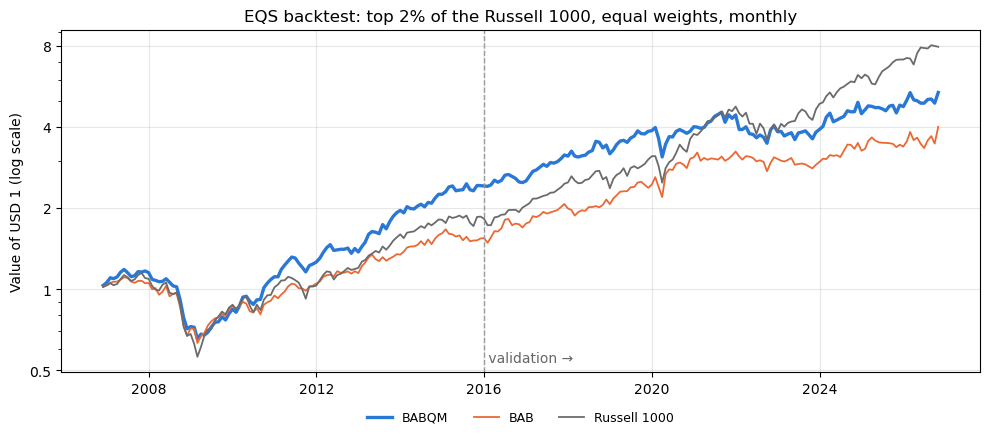

In [2]:
bt = pd.read_csv("r3_backtest.csv", index_col=0, parse_dates=True)    # EQS backtest, monthly returns
rf = pd.read_csv("r3_rf.csv", index_col=0, parse_dates=True)["rf"].reindex(bt.index).ffill()

def stats(r, rf, bench):
    # Class 2 / Class 4 measures of monthly returns r
    ex, exb = r - rf, bench - rf
    T = len(r) / 12                                                   # years
    beta, a = np.polyfit(exb, ex, 1)                                  # CAPM: R^e = a + beta R^e_B + e
    eps = ex - a - beta * exb
    IR  = a * 12 / (eps.std() * np.sqrt(12)) if eps.std() > 0 else np.nan
    if r.equals(bench):                                               # the benchmark against itself
        beta, a, IR = 1.0, 0.0, np.nan
    wealth = (1 + r).cumprod()
    return pd.Series({"mean": r.mean() * 12, "vol": r.std() * np.sqrt(12),
                      "Sharpe": ex.mean() / r.std() * np.sqrt(12), "t(mean)": ex.mean() / r.std() * np.sqrt(12) * np.sqrt(T),
                      "max drawdown": (wealth / wealth.cummax() - 1).min(), "VaR 5% 1m": 1.645 * r.std(),
                      "beta": beta, "alpha": a * 12, "IR": IR, "t(alpha)": IR * np.sqrt(T),
                      "TE vs bench": (r - bench).std() * np.sqrt(12), "total return": wealth.iloc[-1] - 1})

res = bt.apply(lambda r: stats(r, rf, bt[BENCH]))

print(f"BACKTEST {bt.index[0]:%b %Y} - {bt.index[-1]:%b %Y} ({len(bt)} months). One column per strategy:")
print("  mean, vol      : annualized return and volatility")
print("  Sharpe, t(mean): excess return per unit of risk; t > 2 = unlikely to be luck")
print("  max drawdown   : worst fall from a peak; VaR 5% 1m: loss in a bad month (1 in 20)")
print("  beta, alpha    : CAPM on the Russell 1000; alpha = return beyond the market exposure")
print("  IR, t(alpha)   : alpha per unit of extra risk; t > 2 = alpha distinguishable from zero")
display(res)

print("\nCHART: growth of USD 1 invested in each strategy (log scale, so equal slopes = equal returns).")
print(f"Left of the dashed line ({SPLIT}) = design sample; right = validation, the honest test.")

colors = {STRAT: "#2a78d6", "BAB": "#eb6834", "Quality": "#1baf7a", "Momentum": "#eda100", BENCH: "#6b6b6b"}
fig, ax = plt.subplots(figsize=(10, 4.5))
for k in bt:
    ax.plot((1 + bt[k]).cumprod(), color=colors.get(k), lw=2.4 if k == STRAT else 1.3, label=k)
ax.axvline(pd.Timestamp(SPLIT), color="#999", ls="--", lw=1)
ax.text(pd.Timestamp(SPLIT), 0.03, " validation →", transform=ax.get_xaxis_transform(), color="#666")
ax.set_yscale("log"); ax.set_ylabel("Value of USD 1 (log scale)"); ax.grid(alpha=.3)
ax.set_yticks([0.5, 1, 2, 4, 8]); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("EQS backtest: top 2% of the Russell 1000, equal weights, monthly")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

**Reading the results:**
- **Return and risk:** over 20 years BABQM earned **9.5% a year with 14.2% volatility**, against 11.6% and 15.6% for the Russell 1000. Its Sharpe is **0.56** (t = 2.5) against 0.65 for the index.
- **Beta 0.68:** the lower return is about what its lower market exposure predicts. The alpha is **+1.1% a year with t = 0.5**, so it cannot be told apart from zero.
- **What quality and momentum add:** the low-beta rank alone (BAB) earned 7.9% with a Sharpe of 0.46 and a beta of 0.54. The composite earns more per unit of risk but takes more market exposure.
- **Tracking error vs the Russell 1000: 10.8% a year.** The strategy is far from the index, as a top-2% screen should be.

## 4. Validation (Checkpoint 1, part 3)
1. **Split the sample:** use 2006–2015 to develop and tune the strategy, freeze the rule at the end of 2015, then test it on 2016–2026 without further changes.
2. **Count the trials:** the more strategies we test, the more likely one looks good by chance. Even with no true alpha, about 1 test in 20 looks significant at the 5% level. Every backtest we ran is in `Tested Strategies.xlsx`.

In [3]:
periods = {"tuning 2006-2015": bt.loc[:SPLIT], "validation 2016-2026": bt.loc[SPLIT:].iloc[1:]}
val = pd.concat({p: x.apply(lambda r: stats(r, rf.loc[r.index], x[BENCH])) for p, x in periods.items()}, axis=1)

trials = pd.read_csv("r3_trials.csv", index_col=0)                   # notebook 01: the trials log
N_TRIALS = len(trials) + N_EXTRA
print(f"Backtests tried: {N_TRIALS} ({len(trials)} in the trials log + {N_EXTRA} not logged). "
      "With 20 tries and zero alpha, about 1 would look significant at 5%.")
display(trials[["Universe", "Rebalance", "Benchmark", "Sharpe Ratio", "Info Ratio", "Beta", "Status"]])
val.loc[["mean", "vol", "Sharpe", "beta", "alpha", "t(alpha)", "max drawdown"]]

Backtests tried: 9 (9 in the trials log + 0 not logged). With 20 tries and zero alpha, about 1 would look significant at 5%.


,Universe,Rebalance,Benchmark,Sharpe Ratio,Info Ratio,Beta,Status
Strategy Name,,,,,,,
AMC R3 BABQM,Russell 1000 (active),Monthly,RIY,0.5300,-0.2200,0.6600,Tested
MCM Momentun Nov 26,S&P 500 + Morningstar US Total Market + FTSE D...,Monthly,RIY,0.7700,0.2100,1.0600,Promising
AMC R3 MQE,Russell 1000 (active),Monthly,RIY,0.5500,0.1200,1.0400,Tested
"AMC R3 SVQ (Quarterly, vs RIY)",Russell 2000 (active),Quarterly,RIY,0.2900,-0.1200,1.2100,Tested
AMC R3 MWC,Russell 1000 (active),Monthly,RIY,0.4900,0.1000,1.1300,Tested
AMC R3 SVQ,Russell 2000 (active),Monthly,RTY,0.3500,0.0500,1.0900,Tested
AMC R3 BAB,Russell 1000 (active),Monthly,RIY,0.4800,-0.2900,0.4500,Tested
AMC R3 VMQ,Russell 1000 (active),Monthly,RIY,0.4900,0.0200,1.0600,Tested
AMC R3 SCV,Russell 2000 (active),Monthly,RTY,0.3000,0.1100,1.4200,Tested


tuning 2006-2015                      validation 2016-2026  \
                        BABQM     BAB Russell 1000                BABQM   
mean                   0.1063  0.0567       0.0788               0.0848   
vol                    0.1375  0.1316       0.1590               0.1466   
Sharpe                 0.7211  0.3768       0.4510               0.4241   
beta                   0.7034  0.6363       1.0000               0.6558   
alpha                  0.0487  0.0040       0.0000              -0.0201   
t(alpha)               1.8411  0.1423          NaN              -0.6200   
max drawdown          -0.4468 -0.4295      -0.5111              -0.2336   

                                   
                 BAB Russell 1000  
mean          0.0982       0.1481  
vol           0.1447       0.1530  
Sharpe        0.5223       0.8197  
beta          0.4473       1.0000  
alpha         0.0195       0.0000  
t(alpha)      0.5019          NaN  
max drawdown -0.1562      -0.2459

**Reading the results:**
- **Tuning (2006–2015):** Sharpe **0.72** against 0.45 for the index, alpha **+4.9%** (t = 1.8). BAB alone had a Sharpe of 0.38 over the same years, so a rule frozen at the end of 2015 would have chosen BABQM.
- **Validation (2016–2026):** Sharpe **0.42** against 0.82 for the index, alpha **−2.0%** (t = −0.6). These ten years were a strong, high-beta bull market, the regime in which a defensive strategy lags. Over them **BAB alone did better** than BABQM (Sharpe 0.52, alpha about +2%).
- **Interpretation:** performance worsens out of sample and neither alpha is statistically significant. We cannot claim that the strategy beats the market. Its case is a lower-risk equity tilt with a similar return per unit of risk.
- **Trials:** 9 backtests in the log. All of them were run on the full 2006–2026 sample (25 November), so the validation years were already visible when we chose: the split is a check of stability, not a clean out-of-sample test. This is one more reason for the discount in §5.

### Risk (Checkpoint 1, part 3)
Where and when does the strategy lose? We look at the worst months, the largest drawdown, the VaR, and how much of the market's up and down months it captures.

In [4]:
r, b = bt[STRAT], bt[BENCH]
wealth = (1 + r).cumprod()
dd = wealth / wealth.cummax() - 1
trough = dd.idxmin()
peak = wealth.loc[:trough].idxmax()
b_dd = (1 + b.loc[peak:trough].iloc[1:]).prod() - 1                 # the index over the same months
VaR = 1.645 * r.std()
up = b > 0

print(f"Max drawdown {dd.min():.1%}: peak {peak:%b %Y}, bottom {trough:%b %Y} "
      f"(Russell 1000 over the same months: {b_dd:.1%}; its own max drawdown: {res.loc['max drawdown', BENCH]:.1%})")
print(f"VaR 5% 1m = {VaR:.1%}: exceeded in {(r < -VaR).mean():.1%} of the months (5% expected)")
print(f"Average month when the index rises: {r[up].mean():+.1%} vs {b[up].mean():+.1%} "
      f"({r[up].mean() / b[up].mean():.0%} captured)")
print(f"Average month when the index falls: {r[~up].mean():+.1%} vs {b[~up].mean():+.1%} "
      f"({r[~up].mean() / b[~up].mean():.0%} captured)")

worst = r.nsmallest(6).index
print(f"\nThe 6 worst months of {STRAT}:")
pd.DataFrame({STRAT: r[worst], BENCH: b[worst], "difference": r[worst] - b[worst]}).set_index(worst.strftime("%b %Y")).style.format("{:+.1%}")

Max drawdown -44.7%: peak May 2007, bottom Feb 2009 (Russell 1000 over the same months: -50.3%; its own max drawdown: -51.1%)
VaR 5% 1m = 6.8%: exceeded in 4.6% of the months (5% expected)
Average month when the index rises: +2.5% vs +3.4% (72% captured)
Average month when the index falls: -2.5% vs -3.9% (65% captured)

The 6 worst months of BABQM:


,BABQM,Russell 1000,difference
Rebalance Date,,,
Mar 2020,-14.6%,-13.2%,-1.4%
Oct 2008,-14.3%,-17.5%,+3.2%
Jan 2022,-11.7%,-5.6%,-6.0%
Sep 2008,-10.3%,-9.5%,-0.8%
Feb 2009,-9.3%,-10.3%,+1.0%
Dec 2024,-9.3%,-2.8%,-6.5%


**Reading the results:**
- **Max drawdown −44.7%** (peak May 2007, bottom February 2009), against −51.1% for the Russell 1000.
- **The worst months are mostly crashes** (March 2020, September–October 2008, February 2009), and in two of them we lost less than the index. Two of the six were not crashes: **January 2022** (−11.7% vs −5.6%) and **December 2024** (−9.3% vs −2.8%), both months of sharply rising long-term yields. That is the bond-like side of low-beta stocks.
- **Capture:** in an average up month we earn about 72% of the index's gain, in a down month we lose about 65% of its fall. It is a defensive profile, and it costs us in strong rallies (April–May 2026: −2.8% against +15.7%).
- **VaR 6.8%:** exceeded in 4.6% of the months, close to the expected 5%, so the VaR is a fair measure here.
- **Our protection:** long-only, no leverage, large caps, 30 stocks in equal weights, and above all a **limited weight** in the total portfolio (§7).

## 5. The discount (Checkpoint 1, part 3)
Backtests tend to overestimate future performance (Class 4). We **halve the backtested Sharpe Ratio**, and use a larger discount if the result is still above what the validation period delivered:

$$SR^{\text{realistic}} = \frac{SR^{\text{backtest}}}{2}$$

In [5]:
SR_bt  = res.loc["Sharpe", STRAT]
SR_val = val.loc["Sharpe", ("validation 2016-2026", STRAT)]
SR_real = DISCOUNT * SR_bt
print(f"Sharpe: backtest {SR_bt:.2f} | validation period {SR_val:.2f} | realistic (x{DISCOUNT}) {SR_real:.2f} | "
      f"benchmark (Russell 1000) {res.loc['Sharpe', BENCH]:.2f} | trials: {N_TRIALS}")
if SR_real > SR_val:
    print("-> the discounted Sharpe is still above the validation one: use a larger discount")

Sharpe: backtest 0.56 | validation period 0.42 | realistic (x0.5) 0.28 | benchmark (Russell 1000) 0.65 | trials: 9


## 6. Today's portfolio: stocks from the screen
`BEQS` gives the stocks that pass our screen on Saturday 28 November, with the closes of Friday 27 November.

Before investing, **check sector concentration**: a low-beta screen tends to fill up with utilities, consumer staples and health care. We also check whether the screen picks a Round 2 stock: the same stock twice adds risk, not diversification.

In [6]:
import os
if not os.path.exists("r3_holdings.csv"):
    raise FileNotFoundError("r3_holdings.csv is not there yet: run notebook 01 on the Bloomberg file refreshed with "
                            "our screen and tickers (README, step 2). §1-§5 do not need it.")
hold = pd.read_csv("r3_holdings.csv", index_col=0)
missing = sorted((set(ETFS) | set(OLD_SHARES.index)) - set(hold.index))
if missing:
    raise ValueError(f"r3_holdings.csv has no {missing}: it is still the TA's file. Run notebook 01 on the "
                     "Bloomberg file refreshed with our screen and tickers (README, step 2)")
Q = hold[hold["group"] == "Quant"]

print(f"Stocks in the screen today: {len(Q)}")
display(Q[["name", "sector", "px_last", "score"]])

sec = Q["sector"].value_counts(normalize=True)
display(sec.to_frame("share of stocks").style.format("{:.0%}"))
if sec.max() > 0.4:
    print(f"⚠️ {sec.idxmax()} represents {sec.max():.0%} of stocks: high concentration!")
    print("Consider ranking stocks within sectors, or capping each sector (one more trial for §4).")

both = sorted(set(Q.index) & {k for k, w in W_R2.items() if w > 0})
if both:
    print(f"⚠️ the screen also picks Round 2 stocks: {both}. Their quant weight adds to the Round 2 weight (§8)")

Stocks in the screen today: 29


,name,sector,px_last,score
ticker,,,,
MPC,MARATHON PETROLEUM CORP,Energy,359.8000,100.0000
MUSA,MURPHY USA INC,Consumer Discretionary,510.0200,100.0000
HALO,HALOZYME THERAPEUTICS INC,Health Care,94.8000,100.0000
PM,PHILIP MORRIS INTERNATIONAL,Consumer Staples,187.8000,100.0000
MO,ALTRIA GROUP INC,Consumer Staples,76.8900,100.0000
HRB,H&R BLOCK INC,Consumer Discretionary,47.1500,100.0000
VLO,VALERO ENERGY CORP,Energy,329.3900,100.0000
KO,COCA-COLA CO/THE,Consumer Staples,97.4000,100.0000
CF,CF INDUSTRIES HOLDINGS INC,Materials,119.5000,100.0000


,share of stocks
sector,
Energy,31%
Health Care,21%
Consumer Staples,21%
Industrials,10%
Consumer Discretionary,7%
Materials,3%
Financials,3%
Information Technology,3%


## 7. Tracking-error budget, volatility and VaR vs the SAA
**Tracking error (TE)** measures the annualized volatility of the difference between our portfolio's returns and the SAA:

$$TE = \text{sd}(R_{new} - R_S)\sqrt{12}$$

**Guideline:** total TE relative to the SAA must be **≤ 7%**. We target **5%** (`TE_QUANT`) for the Round 2 stocks and the quant sleeve, to leave room for the macro strategy, which the macro notebook sizes on top of this portfolio.

The portfolio combines the SAA, the stocks kept from Round 2 ($A$) and the ~30 quant stocks ($Q$):

$$R_{new} = (1-w_A-w_Q)R_S + w_A R_A + w_Q R_Q \qquad\Rightarrow\qquad R_{new} - R_S = w_A\,(R_A - R_S) + w_Q\,(R_Q - R_S)$$

With $\sigma_j = \text{sd}(R_j - R_S)\sqrt{12}$ the TE of each bet per unit of weight and $\rho$ their correlation:

$$TE^2 = (w_A\sigma_A)^2 + (w_Q\sigma_Q)^2 + 2\rho\,(w_A\sigma_A)(w_Q\sigma_Q)$$

$w_A$ is fixed: **2% of the NAV for each Round 2 stock**, 8% for the four (`W_R2`). We set $TE = 5\%$ and solve for $w_Q$:

$$w_Q = \frac{-\rho\,w_A\sigma_A + \sqrt{5\%^2 - (w_A\sigma_A)^2(1-\rho^2)}}{\sigma_Q}$$

$R_Q$ uses the last 60 monthly returns of **today's** stocks in equal weights (ex ante, as in Rounds 1 and 2), not the backtest returns. Cutting the Round 2 stocks to 2% each frees TE for the quant sleeve; the code prints their weight before and after, and $w_Q$ with no Round 2 stock at all.

**Why not Treynor-Black (Round 2)?** Treynor-Black needs a forward-looking alpha, which we cannot infer from historical backtest returns (Class 3).

**Our sizing decision (28 November): we cap the quant sleeve at 12.5% of the NAV (`W_Q_MAX`).** With the 5% target alone, the formula puts **34%** of the NAV in the quant stocks (printed below), and the macro notebook would add 20% in bonds: more than half of the fund in two strategies whose backtests do not beat their benchmarks. Here, BABQM earned a Sharpe ratio of 0.56 against 0.65 for the Russell 1000, its alpha is not significant (t = 0.5), it earned 0.42 in the validation years, and 0.28 after the ×0.5 discount. The portfolio would also hold 54% of the NAV in equity against 31% in our SAA, and we cannot trade again before 27 December.

So we size each bet to the strength of its evidence: **2% for each Round 2 stock, 12.5% for the quant sleeve, 7.5% for the macro sleeve (macro notebook 02 §5), and the remaining 72% in the SAA**. The 5% target stays as a ceiling, and the cap binds. The tracking error of the whole portfolio is about 2.3%, well inside the 7% budget, and its volatility and VaR are those of the SAA. We set the cap after seeing the composition of the portfolio, not to improve a backtest: the screen, the stocks and their equal weights are unchanged.

In [7]:
prices = pd.read_csv("r3_prices.csv", index_col=0, parse_dates=True)
rf_all = pd.read_csv("r3_rf.csv", index_col=0, parse_dates=True)["rf"]
missing = sorted((set(ETFS) | set(OLD_SHARES.index) | set(Q.index)) - set(prices.columns))
if missing:
    raise ValueError(f"r3_prices.csv has no {missing}: run notebook 01 on the refreshed Bloomberg file")
R   = prices.pct_change(fill_method=None).iloc[1:]
est = R.sub(rf_all.reindex(R.index).ffill(), axis=0).iloc[-WINDOW:]      # monthly excess returns, last 60 months
short = est[Q.index].notna().sum()                                       # months of data for each stock
if (short < WINDOW).any():
    print(f"stocks with fewer than {WINDOW} months (they enter R_Q only when they have data): "
          f"{short[short < WINDOW].to_dict()}")

R_S = est[ETFS] @ W_SAA                                                   # SAA
R_Q = est[Q.index].mean(axis=1)                                           # quant sleeve, equal weights

px    = hold["px_last"]
NAV   = (OLD_SHARES * px[OLD_SHARES.index]).sum() + CASH_R2              # NAV at the 27 Nov closes, checked against PORT (B6)
w_R2  = pd.Series(W_R2, dtype=float)                                    # target weight of each Round 2 stock
KEPT  = list(w_R2[w_R2 > 0].index)
w_A   = w_R2[KEPT].sum()                                                  # fixed: 2% for each kept stock
w_A_old = (OLD_SHARES[list(W_R2)] * px[list(W_R2)]).sum() / NAV           # the Round 2 shares at today's prices
R_A   = est[KEPT] @ (w_R2[KEPT] / w_A) if KEPT else 0 * R_S

# TE per unit of each bet (sigma_A, sigma_Q) and their correlation, as in the formula above
sig_Q = (R_Q - R_S).std() * np.sqrt(12)
sig_A = (R_A - R_S).std() * np.sqrt(12) if KEPT else 0.0
rho   = np.corrcoef(R_A - R_S, R_Q - R_S)[0, 1] if KEPT else 0.0

def te(w_Q, w_A=w_A):
    return (w_A * (R_A - R_S) + w_Q * (R_Q - R_S)).std() * np.sqrt(12)

grid = pd.Series({w: te(w) for w in np.round(np.arange(0, 1 - w_A + 1e-9, 0.005), 3)})
w_Q_te = grid[grid <= TE_QUANT].index.max() if (grid <= TE_QUANT).any() else 0.0   # what the 5% TE target allows
if w_Q_te == 0:
    print(f"⚠️ the kept Round 2 stocks alone use {grid.iloc[0]:.1%} of TE: reduce them to make room")
w_Q  = min(w_Q_te, W_Q_MAX)                                               # our cap binds (markdown above)

a = w_A * sig_A                                                           # closed formula of the markdown (cross-check)
w_formula = (-rho * a + np.sqrt(max(TE_QUANT**2 - a**2 * (1 - rho**2), 0))) / sig_Q
w_Q_alone = TE_QUANT / sig_Q                                              # if we closed every Round 2 stock

R_P = (1 - w_A - w_Q) * R_S + w_A * R_A + w_Q * R_Q
sigma_S, sigma_P, te_P = R_S.std() * np.sqrt(12), R_P.std() * np.sqrt(12), (R_P - R_S).std() * np.sqrt(12)

print(f"SIZING THE QUANT SLEEVE (data: last {len(est)} months, {est.index[0]:%b %Y} - {est.index[-1]:%b %Y})")
print(f"  Portfolio value (NAV)          : USD {NAV:,.0f}")
print(f"  Round 2 stocks kept            : {', '.join(KEPT) if KEPT else 'none'} -> {w_A:.1%} of the NAV "
      f"(Round 2 shares today: {w_A_old:.1%}), TE alone {a:.1%}, correlation with the quant bet {rho:+.2f}")
print(f"  TE if 100% in the quant stocks : {sig_Q:.1%}  (how far the {len(Q)} stocks move away from the SAA)")
print(f"  Weight in the quant stocks     : {w_Q:.1%} of the NAV -> TE = {te(w_Q):.1%}"
      + (f"   (capped by W_Q_MAX: the {TE_QUANT:.0%} TE target alone allows {w_Q_te:.1%}; closed formula {w_formula:.1%})"
         if w_Q < w_Q_te else f" (target {TE_QUANT:.0%}; closed formula {w_formula:.1%}; with no Round 2 stock {w_Q_alone:.1%})"))
print(f"  Left in the SAA                : {1 - w_A - w_Q:.1%} of the NAV")

print("\nRISK OF THE NEW PORTFOLIO vs the SAA")
pd.DataFrame({"SAA": [sigma_S, 1.645 * sigma_S / np.sqrt(12), 0.0],
              "Round 3 (before macro)": [sigma_P, 1.645 * sigma_P / np.sqrt(12), te_P]},
             index=["Volatility (annual)", "VaR 5%, 1 month", "Tracking error vs SAA"]).style.format("{:.1%}")

SIZING THE QUANT SLEEVE (data: last 60 months, Nov 2021 - Oct 2026)


  Portfolio value (NAV)          : USD 96,827,577
  Round 2 stocks kept            : NVDA, PEP, ABBV, DRI -> 8.0% of the NAV (Round 2 shares today: 22.6%), TE alone 1.1%, correlation with the quant bet +0.26
  TE if 100% in the quant stocks : 13.4%  (how far the 29 stocks move away from the SAA)
  Weight in the quant stocks     : 12.5% of the NAV -> TE = 2.2%   (capped by W_Q_MAX: the 5% TE target alone allows 34.0%; closed formula 34.5%)
  Left in the SAA                : 79.5% of the NAV

RISK OF THE NEW PORTFOLIO vs the SAA


,SAA,Round 3 (before macro)
Volatility (annual),8.4%,8.7%
"VaR 5%, 1 month",4.0%,4.1%
Tracking error vs SAA,0.0%,2.2%


## 8. Portfolio description and trades (for the report and PRTU)

The new weights, for the three kinds of positions:

| Position | New weight | In words |
|---|---|---|
| each SAA ETF $j$ (VTI, VEA, …, BCI) | $w^{new}_j = (1 - w_A - w_Q)\cdot w^{SAA}_j$ | the money left for the SAA, split as in Round 1 |
| each Round 2 stock $k$ (NVDA, PEP, ABBV, DRI) | $w^{new}_k = 2\%$ | the weight we chose (`W_R2`; 0 would close it): the four add up to $w_A = 8\%$, so we sell part of each Round 2 position |
| each quant stock $i$ (the $N_Q$ stocks of the screen) | $w^{new}_i = \dfrac{w_Q}{N_Q}$ | equal weights |

From weights to shares and trades, for every position:

$$\text{shares}^{new} = \left\lfloor \frac{w^{new}\cdot \text{NAV}}{P}\right\rfloor, \qquad \text{trade} = \text{shares}^{new} - \text{shares}^{old}$$

$P$ = the close of Friday 27 November, $\lfloor\cdot\rfloor$ = round down (whole shares; the remainder stays in cash). A trade > 0 is a **buy**, < 0 a **sell**. **Every SAA ETF is cut by the same factor $(1 - w_A - w_Q)$, so the SAA mix does not change.**

`r3_portfolio.csv` is the input of the macro notebook, which adds the macro sleeve and writes the final trades for PRTU. Its `sleeve` column tells the macro notebook which stocks are quant and which are Round 2.

In [8]:
w_new = pd.concat([(1 - w_A - w_Q) * W_SAA, w_R2[KEPT], pd.Series(w_Q / len(Q), index=Q.index)]).groupby(level=0).sum()
tick  = w_new.index.union(OLD_SHARES.index)                               # include the closed positions
r2    = [t for t in OLD_SHARES.index if t not in ETFS]
sleeve = pd.Series([("SAA" if t in ETFS else "Round 2 + Quant" if t in r2 and t in Q.index
                     else "Round 2" if t in r2 else "Quant") for t in tick], index=tick)
port  = pd.DataFrame({"name": hold["name"].reindex(tick),
                      "Bloomberg": [t + " Equity" if " " in t else t + " US Equity" for t in tick],
                      "currency": "USD", "sleeve": sleeve, "weight": w_new.reindex(tick).fillna(0),
                      "price": px.reindex(tick), "price date": PRICE_DATE}, index=tick)
port["shares"]     = np.floor(port["weight"] * NAV / port["price"] + 1e-9)
port["old shares"] = OLD_SHARES.reindex(tick).fillna(0)
port["trade"]      = port["shares"] - port["old shares"]                  # > 0 buy, < 0 sell
port["USD"]        = port["shares"] * port["price"]
port.loc["CASH", ["sleeve", "weight", "USD"]] = ["Cash", 1 - port["weight"].sum(), NAV - port["USD"].sum()]
port.to_csv("r3_portfolio.csv")

assert te_P <= TE_MAX, f"TE {te_P:.2%} above the {TE_MAX:.0%} budget"
print(f"Prices of {PRICE_DATE} | NAV = USD {NAV:,.0f} | positions: {(port['shares'] > 0).sum()} | "
      f"trades: {(port['trade'].fillna(0) != 0).sum()} | TE vs SAA: {te_P:.2%} (budget {TE_MAX:.0%})")
print("Weight by sleeve:", port.groupby("sleeve")["weight"].sum().round(4).to_dict())
port.sort_values("weight", ascending=False)

Prices of 2026-11-27 | NAV = USD 96,827,577 | positions: 41 | trades: 41 | TE vs SAA: 2.21% (budget 7%)
Weight by sleeve: {'Cash': 0.0001, 'Quant': 0.125, 'Round 2': 0.08, 'SAA': 0.7949}


,name,Bloomberg,currency,sleeve,weight,price,price date,shares,old shares,trade,USD
BNDX,VANGUARD TOTAL INTL BOND ETF,BNDX US Equity,USD,SAA,0.1310,47.6100,2026-11-27,266455.0000,265436.0000,1019.0000,12685922.5500
TIP,ISHARES TIPS BOND ETF,TIP US Equity,USD,SAA,0.1213,105.6700,2026-11-27,111165.0000,110068.0000,1097.0000,11746805.5500
BND,VANGUARD TOTAL BOND MARKET,BND US Equity,USD,SAA,0.1060,71.3800,2026-11-27,143753.0000,142724.0000,1029.0000,10261089.1400
BCI,ABRDN BLOOMBERG ALL COMMODIT,BCI US Equity,USD,SAA,0.0986,23.5700,2026-11-27,404975.0000,385745.0000,19230.0000,9545260.7500
GLD,SPDR GOLD SHARES,GLD US Equity,USD,SAA,0.0886,334.4000,2026-11-27,25666.0000,22942.0000,2724.0000,8582710.4000
VTI,VG MORNINGSTAR TS MKT ETF-US,VTI US Equity,USD,SAA,0.0867,359.4000,2026-11-27,23346.0000,23084.0000,262.0000,8390552.4000
VEA,VANGUARD FTSE DEVELOPED ETF,VEA US Equity,USD,SAA,0.0814,66.8600,2026-11-27,117896.0000,115597.0000,2299.0000,7882526.5600
IEMG,ISHARES CORE MSCI EMERGING,IEMG US Equity,USD,SAA,0.0813,70.8400,2026-11-27,111163.0000,108607.0000,2556.0000,7874786.9200
NVDA,NVIDIA CORP,NVDA US Equity,USD,Round 2,0.0200,150.4900,2026-11-27,12868.0000,9618.0000,3250.0000,1936505.3200
ABBV,ABBVIE INC,ABBV US Equity,USD,Round 2,0.0200,291.8800,2026-11-27,6634.0000,19594.0000,-12960.0000,1936331.9200
